# Notes EA SPORTS FC et valeur marchande

La note FIFA (EA SPORTS FC) et la valeur marchande Transfermarkt sont deux évaluations du même
joueur, faites par des acteurs différents : la première mesure le **niveau actuel** du joueur
dans le jeu, la seconde le **prix** auquel il pourrait être transféré. Elles ne dépendent pas
l'une de l'autre : on cherche ce qu'elles récompensent en commun, et surtout **où et pourquoi
elles divergent**.

**Sommaire**

- Partie A : les notes FIFA
  - [A0. Préparation des données](#A0.-Préparation-des-données)
  - [A1. Distribution des notes](#A1.-Distribution-des-notes)
  - [A2. Note, âge, poste et championnat](#A2.-Note,-âge,-poste-et-championnat)
  - [A3. Note et performances réelles](#A3.-Note-et-performances-réelles)
- Partie B : comparaison avec la valeur marchande
  - [B1. Le lien entre note et valeur](#B1.-Le-lien-entre-note-et-valeur)
  - [B2. Mêmes facteurs, poids différents](#B2.-Mêmes-facteurs,-poids-différents)
  - [B3. Écart entre le marché et FIFA](#B3.-Écart-entre-le-marché-et-FIFA)
  - [B4. Évolution sur quatre saisons](#B4.-Évolution-sur-quatre-saisons)

# Partie A : les notes FIFA

## A0. Préparation des données

On reprend les joueurs de l'analyse des valeurs marchandes (au moins 900 minutes jouées en
2025-26) et on leur associe leur note dans **EA SPORTS FC 27**. Cette édition est sortie en
septembre 2026 : sa note reflète la saison 2025-26, comme la valeur au 30 juin 2026.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

from valeur_marchande.transfermarkt import load_snapshot, load_panel
from valeur_marchande.ea_fc import load_matched, add_ratings_to_panel
from valeur_marchande.analyse import (ORDRE_POSTES, FACTEURS, preparer_joueurs,
                                      tableau_coefficients, importance_facteurs)

In [2]:
joueurs = preparer_joueurs(load_snapshot())
notes = load_matched()   # une ligne par joueur et par édition (FIFA 23 à FC 27)

notes["edition"].value_counts()

edition
fc24      6385
fc27      6310
fc26      6118
fifa23    6117
fc25      5793
Name: count, dtype: int64

In [3]:
COLONNES_NOTES = ["player_id", "overall_rating", "pace", "shooting", "passing",
                  "dribbling", "defending", "physical"]
notes_fc27 = notes.loc[notes["edition"] == "fc27", COLONNES_NOTES]
joueurs_notes = joueurs.merge(notes_fc27, on="player_id")
joueurs_notes = joueurs_notes.rename(columns={"overall_rating": "note"})

print(f"{len(joueurs_notes)} joueurs avec une note FC 27, sur {len(joueurs)} "
      f"({len(joueurs_notes) / len(joueurs):.0%})")

2678 joueurs avec une note FC 27, sur 2942 (91%)


Les joueurs sans note sont ceux que le rapprochement entre Transfermarkt et EA n'a pas
retrouvés (nom ou date de naissance trop différents, joueur absent du jeu). Sont-ils différents
des autres ?

In [4]:
joueurs["a_une_note"] = joueurs["player_id"].isin(notes_fc27["player_id"])
joueurs.groupby("a_une_note")[["valeur_millions", "age", "minutes_2025_26"]].median()

,valeur_millions,age,minutes_2025_26
a_une_note,,,
False,0.9,29.0,1527.0
True,6.0,26.0,2169.5


91 % des joueurs de l'analyse (2 678 sur 2 942) ont une note FC 27. Les joueurs sans note sont vraiment moins valorisés (valeur médiane de 0,9 M€ contre 6,0 M€), un peu plus âgés (29 ans contre 26) et jouent moins (1 527 minutes contre 2 170). Il s'agit surtout de joueurs moins connus, ou absents du jeu. L'échantillon étudié est donc orienté vers les bons joueurs : c'est une limite à garder en tête, les résultats suivants portent surtout sur les joueurs les mieux valorisés.

## A1. Distribution des notes

In [5]:
joueurs_notes["note"].describe().round(1)

count    2678.0
mean       74.7
std         5.2
min        55.0
25%        71.0
50%        75.0
75%        78.0
max        91.0
Name: note, dtype: float64

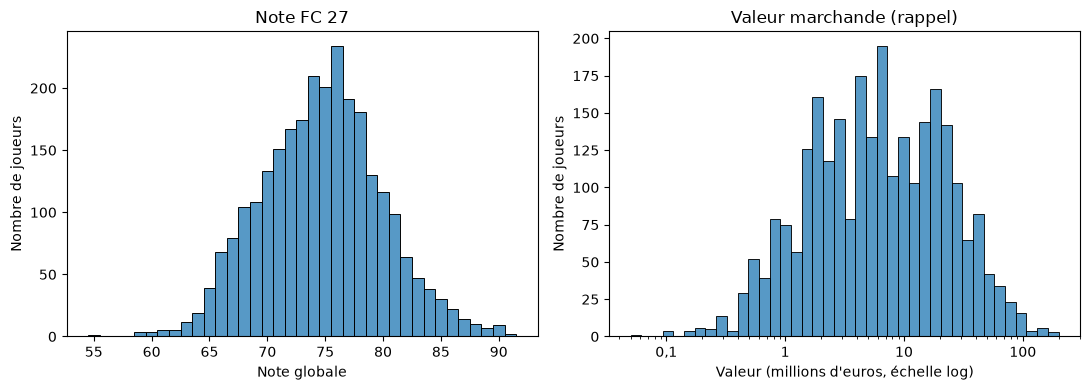

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(data=joueurs_notes, x="note", discrete=True, ax=axes[0])
axes[0].set(title="Note FC 27", xlabel="Note globale", ylabel="Nombre de joueurs")

sns.histplot(data=joueurs_notes, x="valeur_millions", bins=40, log_scale=True, ax=axes[1])
axes[1].set_xticks([0.1, 1, 10, 100], labels=["0,1", "1", "10", "100"])
axes[1].set(title="Valeur marchande (rappel)", xlabel="Valeur (millions d'euros, échelle log)",
            ylabel="Nombre de joueurs")

plt.tight_layout()
plt.show()

La note moyenne bouge-t-elle d'une édition à l'autre ? (tous les joueurs appariés)

In [7]:
ORDRE_EDITIONS = ["fifa23", "fc24", "fc25", "fc26", "fc27"]
(
    notes
    .groupby("edition")["overall_rating"]
    .agg(["count", "mean", "median"])
    .loc[ORDRE_EDITIONS]
    .round(1)
)

,count,mean,median
edition,,,
fifa23,6117,69.9,70.0
fc24,6385,69.8,70.0
fc25,5793,70.7,71.0
fc26,6118,70.6,70.0
fc27,6310,70.6,70.0


La note FC 27 des 2 678 joueurs est resserrée et à peu près symétrique : la moyenne est de 74,7 (et médiane 75, écart-type 5,2), et la moitié des joueurs ont une note entre 71 et 78, pour des notes allant de 55 à 91. La valeur marchande, au contraire, s'étale sur plusieurs puissances de 10. La note est donc une échelle fermée qui distingue relativement peu les meilleurs joueurs : quelques points d'écart au sommet de l'échelle peuvent correspondre à une valeur deux ou trois fois plus élevée. L'échelle est stable d'une édition à l'autre : sur l'ensemble des joueurs appariés, la note moyenne reste autour de 70 de FIFA 23 à FC 27, ce qui permet de comparer les éditions. Notre échantillon a une moyenne plus haute (74,7) car on ne garde que les joueurs ayant joué au moins 900 minutes dans les grands championnats, qui sont en moyenne meilleurs.

## A2. Note, âge, poste et championnat

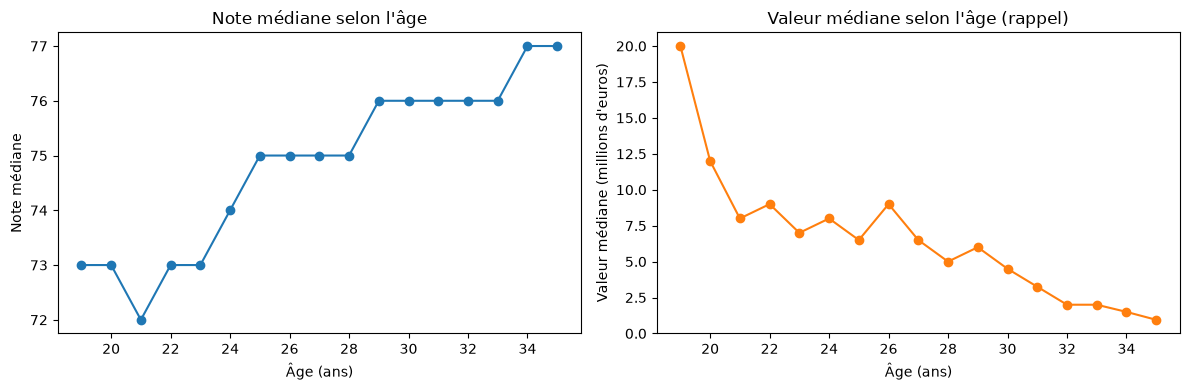

In [8]:
effectifs_age = joueurs_notes["age"].value_counts()
ages_retenus = effectifs_age[effectifs_age >= 20].index
par_age = (
    joueurs_notes
    .loc[joueurs_notes["age"].isin(ages_retenus)]
    .groupby("age")[["note", "valeur_millions"]]
    .median()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(par_age.index, par_age["note"], marker="o")
axes[0].set(title="Note médiane selon l'âge", xlabel="Âge (ans)", ylabel="Note médiane")
axes[1].plot(par_age.index, par_age["valeur_millions"], marker="o", color="tab:orange")
axes[1].set(title="Valeur médiane selon l'âge (rappel)", xlabel="Âge (ans)",
            ylabel="Valeur médiane (millions d'euros)")
plt.tight_layout()
plt.show()

In [9]:
ordre_championnats = (
    joueurs_notes
    .groupby("championnat")["note"]
    .median()
    .sort_values(ascending=False)
    .index
)
pd.pivot_table(joueurs_notes, values="note", index="championnat", columns="poste",
               aggfunc="median").loc[ordre_championnats, ORDRE_POSTES]

poste,Gardien,Défenseur,Milieu,Attaquant
championnat,,,,
Premier League,79.0,79.0,79.0,78.5
Bundesliga,78.0,75.0,76.0,76.0
Liga,79.0,76.0,76.0,76.0
Serie A,77.0,75.0,75.0,76.0
Ligue 1,78.0,75.0,75.0,76.0
Liga Portugal,72.5,70.0,71.0,72.0
Eredivisie,71.0,70.0,69.0,70.0
Pro League,71.0,70.0,71.0,70.0
Süper Lig,69.5,70.0,69.0,71.0


Selon l'âge, la note et la valeur évoluent en sens inverse. La note médiane augmente légèrement, de 73 à 19 ans à 77 à 35 ans, alors que la valeur médiane s'effondre : environ 20 M€ à 19 ans, 8 M€ à 24 ans et 1 M€ à 35 ans, soit une division par 20. La hausse de la note est en partie un effet de sélection : les joueurs âgés qui jouent encore au moins 900 minutes sont les meilleurs de leur génération. C'est une première grande différence entre les deux évaluations : FIFA note seulement le niveau actuel du joueur, alors que le marché paie aussi son avenir. Le classement des championnats est en revanche presque le même que pour la valeur : la note médiane va d'environ 79 en Premier League à environ 70 en Eredivisie, en Pro League et en Süper Lig, avec la Liga, la Bundesliga, la Serie A et la Ligue 1 entre les deux. Enfin, les gardiens ont des notes égales ou supérieures à celles des joueurs de champ dans presque tous les championnats.